#### Activity 9 ANN MLP

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [2]:
#1. Generate realistic e-governance district data
np.random.seed(42)
n_districts = 400
internet_penetration = np.random.uniform (20, 95, n_districts) # %
literacy_rate = np.random.uniform (40, 99, n_districts)
avg_bandwidth = np.random.exponential(15, n_districts) # Mbps
public_kiosks = np.random.randint(1, 25, n_districts) # Count per 10k citizens

In [3]:
success_rule = (
((internet_penetration > 60) & (literacy_rate > 70)) |
(public_kiosks > 18) |
((avg_bandwidth > 22) & (literacy_rate > 60))
)
y = success_rule.astype(int)
#Combine into a feature matrix X
X = np.column_stack([internet_penetration, literacy_rate, avg_bandwidth, public_kiosks])

In [4]:
df = pd.DataFrame(X, columns=['Internet Penetration', 'Literacy Rate', 'Avg Bandwidth', 'Public Kiosks'])
df["Success"] = y
df.head()

,Internet Penetration,Literacy Rate,Avg Bandwidth,Public Kiosks,Success
0,48.090509,46.084308,18.425962,12.0,0
1,91.303573,93.250621,2.482658,7.0,1
2,74.899546,69.809890,12.880532,11.0,0
3,64.899386,88.760991,13.998313,1.0,1
4,31.701398,58.882926,8.278118,6.0,0


<Axes: >

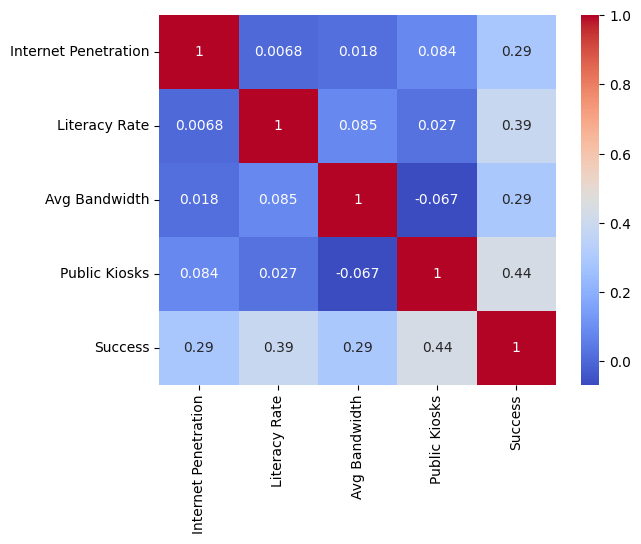

In [5]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

In [6]:
# sns.pairplot(df, hue="Success", diag_kind="kde")

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((320, 4), (80, 4), (320,), (80,))

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
MLP_model = MLPClassifier(hidden_layer_sizes=(10), max_iter=1000, random_state=42, activation='relu')
MLP_model.fit(X_train_scaled, y_train)

,hidden_layer_sizes,10
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,42


In [10]:
print("Input neurons:", MLP_model.n_features_in_)
print("Hidden layers:", MLP_model.hidden_layer_sizes)
print("Output neurons:", MLP_model.n_outputs_)
print("Total layers:", MLP_model.n_layers_)
print("Output activation:", MLP_model.out_activation_)
print("Classes:", MLP_model.classes_)

Input neurons: 4
Hidden layers: 10
Output neurons: 1
Total layers: 3
Output activation: logistic
Classes: [0 1]


In [11]:
accuracy = MLP_model.score(X_train_scaled, y_train)
accuracy

0.96875

In [12]:
accuracy = MLP_model.score(X_test_scaled, y_test)
accuracy

0.9125

<Axes: >

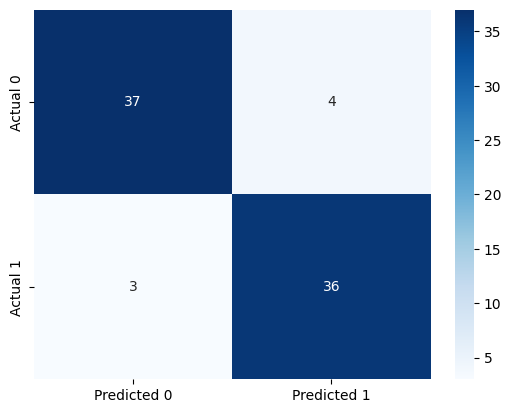

In [13]:
confusion_mtx = confusion_matrix(y_test, MLP_model.predict(X_test_scaled))
sns.heatmap(confusion_mtx, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1'], yticklabels=['Actual 0', 'Actual 1'])

In [14]:
from pprint import pprint

report = classification_report(
    y_test,
    MLP_model.predict(X_test_scaled),
    output_dict=True
)

pprint(report)

{'0': {'f1-score': 0.9135802469135802,
       'precision': 0.925,
       'recall': 0.9024390243902439,
       'support': 41.0},
 '1': {'f1-score': 0.9113924050632911,
       'precision': 0.9,
       'recall': 0.9230769230769231,
       'support': 39.0},
 'accuracy': 0.9125,
 'macro avg': {'f1-score': 0.9124863259884357,
               'precision': 0.9125000000000001,
               'recall': 0.9127579737335836,
               'support': 80.0},
 'weighted avg': {'f1-score': 0.9125136740115642,
                  'precision': 0.9128125,
                  'recall': 0.9125,
                  'support': 80.0}}


In [15]:
display(
    pd.DataFrame(report).T.style
    .format("{:.3f}")
    .background_gradient(cmap="RdYlGn", subset=["precision", "recall", "f1-score"])
)

,precision,recall,f1-score,support
0,0.925,0.902,0.914,41.000
1,0.900,0.923,0.911,39.000
accuracy,0.912,0.912,0.912,0.912
macro avg,0.913,0.913,0.912,80.000
weighted avg,0.913,0.912,0.913,80.000
